<a href="https://colab.research.google.com/github/rudrapratapbarik257-arch/YBI-FOUNDATION-INTERNSHIP/blob/main/Indian_Movies_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Indian Movies Recommendation System
### Data Science and Machine Learning YBI foundation internship Project

This project recommends movies that have similar genres and languages.

**Dataset:** `indian movies.csv`

**Machine Learning method:** Content-Based Filtering using TF-IDF and Cosine Similarity.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Upload the Dataset

In [2]:
from google.colab import files
uploaded = files.upload()

Saving indian movies.csv to indian movies.csv


In [3]:
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (50602, 8)


,ID,Movie Name,Year,Timing(min),Rating(10),Votes,Genre,Language
0,tt0398974,Dr. Shaitan,1960,-,-,-,-,hindi
1,tt1702558,Nadir Khan,1968,-,-,-,-,urdu
2,tt0493437,Apna Sapna Money Money,2006,134 min,5.3,"1,892","Comedy, Musical, Romance",hindi
3,tt0273405,Aag Aur Sholay,1987,-,2.2,20,-,urdu
4,tt0049595,Parivar,1956,-,7.4,21,"Comedy, Drama, Family",hindi


## 3. Understand the Dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50602 entries, 0 to 50601
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           50602 non-null  object
 1   Movie Name   50602 non-null  object
 2   Year         49041 non-null  object
 3   Timing(min)  50602 non-null  object
 4   Rating(10)   50602 non-null  object
 5   Votes        50602 non-null  object
 6   Genre        50602 non-null  object
 7   Language     50602 non-null  object
dtypes: object(8)
memory usage: 3.1+ MB


In [5]:
df.describe(include="all")

,ID,Movie Name,Year,Timing(min),Rating(10),Votes,Genre,Language
count,50602,50602,49041,50602,50602,50602,50602,50602
unique,46106,42442,579,259,92,2951,718,19
top,-,Alif Laila,2018,-,-,-,Drama,hindi
freq,2508,167,1934,25892,26926,26925,13529,14350


In [6]:
print("Columns in the dataset:")
print(df.columns.tolist())

print("\\nMissing values:")
print(df.isnull().sum())

Columns in the dataset:
['ID', 'Movie Name', 'Year', 'Timing(min)', 'Rating(10)', 'Votes', 'Genre', 'Language']
\nMissing values:
ID                0
Movie Name        0
Year           1561
Timing(min)       0
Rating(10)        0
Votes             0
Genre             0
Language          0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 4. Clean the Dataset

In [8]:
# Replace '-' and blank values with missing values
df = df.replace(r"^\\s*-\\s*$", np.nan, regex=True)
df = df.replace(r"^\\s*$", np.nan, regex=True)

# Remove extra spaces from text columns
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

df.head()

,ID,Movie Name,Year,Timing(min),Rating(10),Votes,Genre,Language
0,tt0398974,Dr. Shaitan,1960,-,-,-,-,hindi
1,tt1702558,Nadir Khan,1968,-,-,-,-,urdu
2,tt0493437,Apna Sapna Money Money,2006,134 min,5.3,"1,892","Comedy, Musical, Romance",hindi
3,tt0273405,Aag Aur Sholay,1987,-,2.2,20,-,urdu
4,tt0049595,Parivar,1956,-,7.4,21,"Comedy, Drama, Family",hindi


In [9]:
# Convert year, rating and votes into numeric values
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Rating(10)"] = pd.to_numeric(df["Rating(10)"], errors="coerce")

df["Votes"] = pd.to_numeric(
    df["Votes"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Remove 'min' from movie timing
df["Timing(min)"] = pd.to_numeric(
    df["Timing(min)"].astype(str).str.replace(" min", "", regex=False),
    errors="coerce"
)

df[["Year", "Timing(min)", "Rating(10)", "Votes"]].head()

,Year,Timing(min),Rating(10),Votes
0,1960.0,NaN,NaN,NaN
1,1968.0,NaN,NaN,NaN
2,2006.0,134.0,5.3,1892.0
3,1987.0,NaN,2.2,20.0
4,1956.0,NaN,7.4,21.0


In [10]:
# Keep rows that have a movie name and genre
movies = df.dropna(subset=["Movie Name", "Genre"]).copy()

# Remove empty movie names and genres
movies = movies[
    (movies["Movie Name"].str.strip() != "") &
    (movies["Genre"].str.strip() != "")
]

# Fill missing language with 'unknown'
movies["Language"] = movies["Language"].fillna("unknown")

# Make genre and language text consistent
movies["Genre"] = movies["Genre"].str.lower().str.strip()
movies["Language"] = movies["Language"].str.lower().str.strip()

# Remove duplicate movie entries
movies = movies.drop_duplicates(
    subset=["Movie Name", "Year", "Language"]
).reset_index(drop=True)

print("Rows after cleaning:", movies.shape[0])
movies.head()

Rows after cleaning: 49811


,ID,Movie Name,Year,Timing(min),Rating(10),Votes,Genre,Language
0,tt0398974,Dr. Shaitan,1960.0,NaN,NaN,NaN,-,hindi
1,tt1702558,Nadir Khan,1968.0,NaN,NaN,NaN,-,urdu
2,tt0493437,Apna Sapna Money Money,2006.0,134.0,5.3,1892.0,"comedy, musical, romance",hindi
3,tt0273405,Aag Aur Sholay,1987.0,NaN,2.2,20.0,-,urdu
4,tt0049595,Parivar,1956.0,NaN,7.4,21.0,"comedy, drama, family",hindi


## 5. Explore the Dataset

In [11]:
print("Number of movies:", len(movies))
print("Number of languages:", movies["Language"].nunique())
print("Number of genres:", movies["Genre"].nunique())

Number of movies: 49811
Number of languages: 19
Number of genres: 718


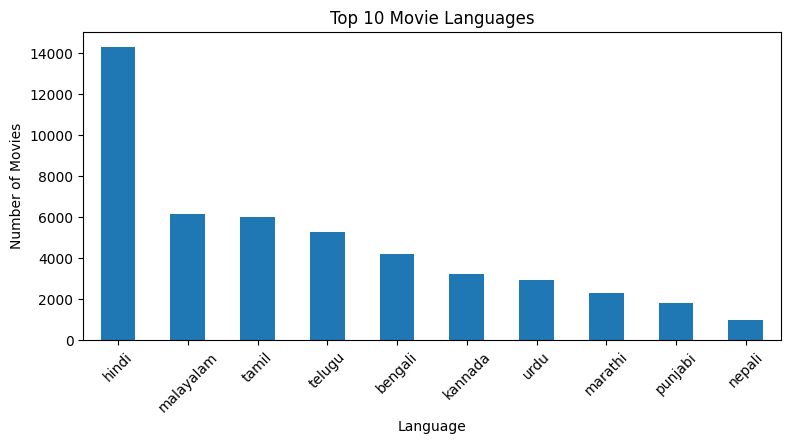

In [12]:
# Top 10 languages
movies["Language"].value_counts().head(10).plot(
    kind="bar", figsize=(9, 4)
)
plt.title("Top 10 Movie Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

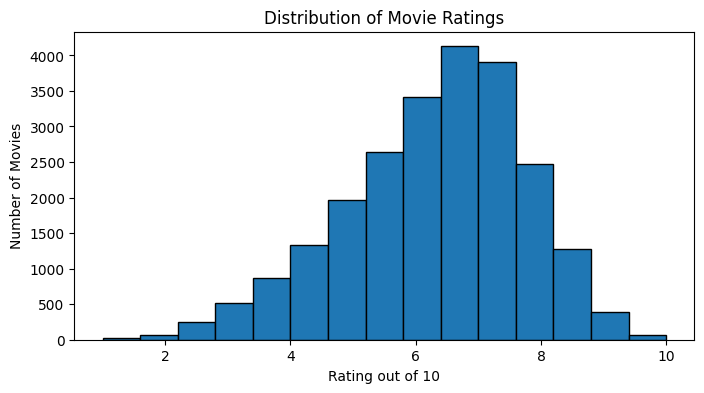

In [13]:
# Movie rating distribution
movies["Rating(10)"].dropna().plot(
    kind="hist", bins=15, figsize=(8, 4), edgecolor="black"
)
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating out of 10")
plt.ylabel("Number of Movies")
plt.show()

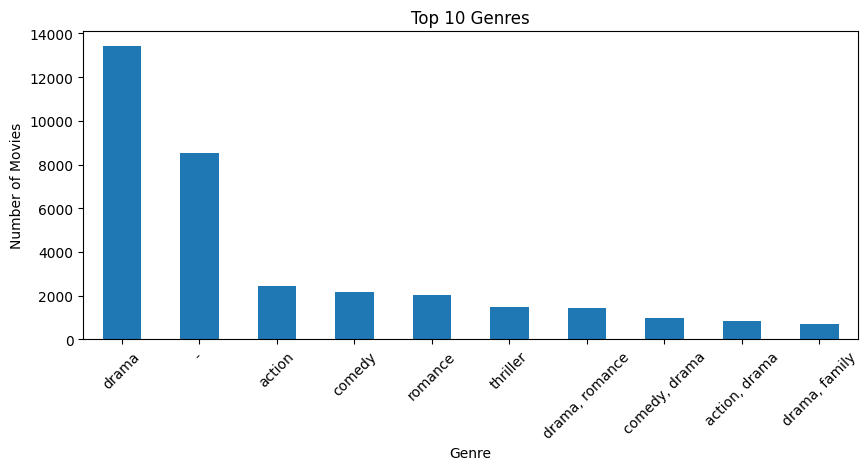

In [14]:
# Top 10 genres
movies["Genre"].value_counts().head(10).plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Top 10 Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

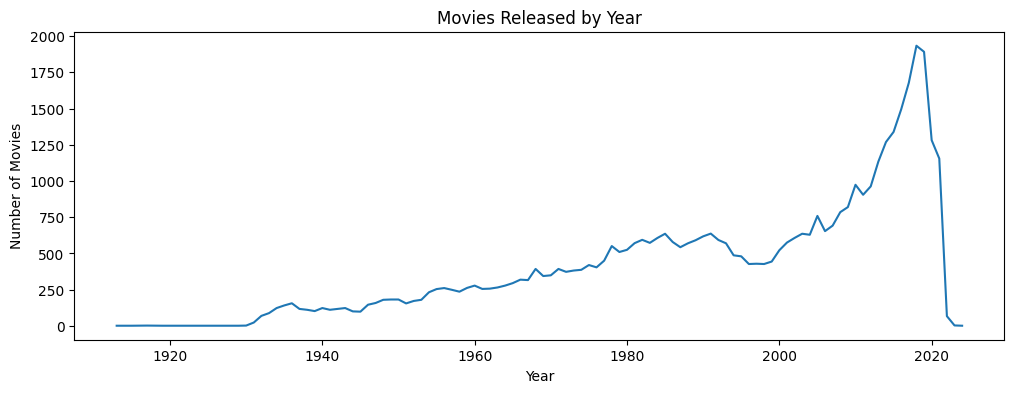

In [15]:
# Number of movies released in each year
year_counts = movies["Year"].dropna().astype(int).value_counts().sort_index()

plt.figure(figsize=(12, 4))
year_counts.plot()
plt.title("Movies Released by Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.show()

## 6. Prepare Movie Features

In [16]:
# Use genre and language to describe each movie
movies["Language"] = movies["Language"].fillna("unknown")

movies["features"] = (
    movies["Genre"].fillna("").str.lower() + " " +
    movies["Language"].fillna("").str.lower()
)

movies[["Movie Name", "Genre", "Language", "features"]].head()

,Movie Name,Genre,Language,features
0,Dr. Shaitan,-,hindi,- hindi
1,Nadir Khan,-,urdu,- urdu
2,Apna Sapna Money Money,"comedy, musical, romance",hindi,"comedy, musical, romance hindi"
3,Aag Aur Sholay,-,urdu,- urdu
4,Parivar,"comedy, drama, family",hindi,"comedy, drama, family hindi"


## 7. Convert Text into Numbers with TF-IDF

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
feature_matrix = tfidf.fit_transform(movies["features"])

print("TF-IDF matrix shape:", feature_matrix.shape)

TF-IDF matrix shape: (49811, 48)


## 8. Find Similar Movies

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(feature_matrix)

print("Similarity matrix created!")

## 9. Build the Recommendation Function

In [ ]:
def recommend_movies(movie_name, number_of_recommendations=5):
    # Search for the movie without considering capital letters
    matching_movies = movies[
        movies["Movie Name"].str.lower() == movie_name.strip().lower()
    ]

    if matching_movies.empty:
        print("Movie not found. Please check the spelling.")
        return None

    # Use the first matching movie
    movie_index = matching_movies.index[0]

    # Get similarity scores for all movies
    scores = list(enumerate(similarity_matrix[movie_index]))

    # Sort movies from most similar to least similar
    scores = sorted(scores, key=lambda item: item[1], reverse=True)

    # Remove the selected movie from the results
    scores = [
        item for item in scores
        if item[0] != movie_index
    ]

    # Select the requested number of recommendations
    scores = scores[:number_of_recommendations]

    recommendations = []

    for index, score in scores:
        movie = movies.iloc[index]

        recommendations.append({
            "Movie Name": movie["Movie Name"],
            "Year": movie["Year"],
            "Genre": movie["Genre"],
            "Language": movie["Language"],
            "Rating": movie["Rating(10)"],
            "Similarity Score": round(float(score), 3)
        })

    return pd.DataFrame(recommendations)

## 10. Test the Recommendation System

In [ ]:
# Display some movie names that can be used for testing
movies[["Movie Name", "Year", "Genre"]].head(10)

In [ ]:
# Try the first movie in the dataset
sample_movie = movies.iloc[0]["Movie Name"]
print("Selected movie:", sample_movie)

recommend_movies(sample_movie, 5)

In [ ]:
# Search for any movie by entering its name
movie_name = input("Enter a movie name: ")
result = recommend_movies(movie_name, 5)

if result is not None:
    display(result)

## 11. Display Top Rated Movies

In [ ]:
# Show movies that have a rating and at least 10 votes
popular_movies = movies.dropna(subset=["Rating(10)", "Votes"])
popular_movies = popular_movies[popular_movies["Votes"] >= 10]

top_movies = popular_movies.sort_values(
    by=["Rating(10)", "Votes"],
    ascending=False
)

top_movies[
    ["Movie Name", "Year", "Genre", "Language", "Rating(10)", "Votes"]
].head(10)

## 12. Save the Cleaned Dataset

In [ ]:
movies.drop(columns=["features"], errors="ignore").to_csv(
    "cleaned_indian_movies.csv", index=False
)

print("Cleaned dataset saved successfully!")

In [ ]:
from google.colab import files
files.download("cleaned_indian_movies.csv")

## 13. Conclusion

In this project, we created a movie recommendation system using the Indian movies dataset.

- We cleaned the dataset and explored movie ratings, genres and languages.
- TF-IDF converted genre and language details into numerical features.
- Cosine Similarity compared movies and found similar ones.
- The recommendation function suggests movies based on a movie name entered by the user.

**Limitation:** The dataset does not contain movie descriptions, actors or directors. Therefore, recommendations are mainly based on genre and language. Movies with the same genre and language may receive similar scores.